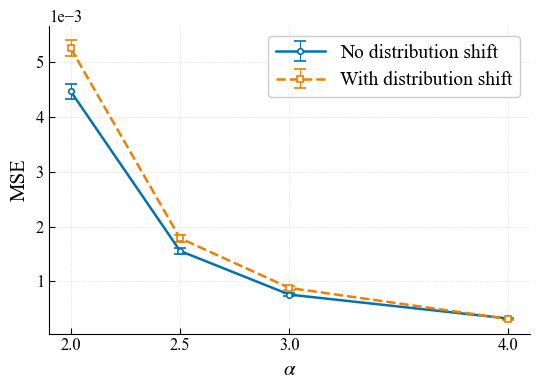

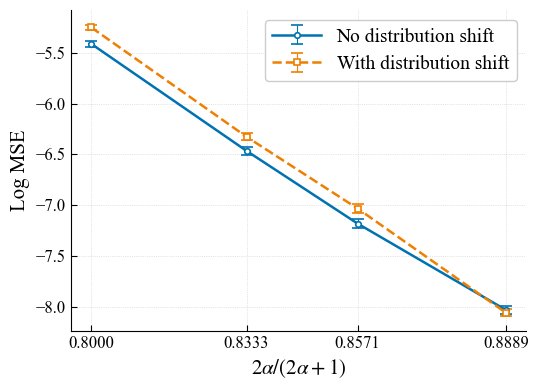

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

test = pd.read_csv("test_results_new.csv")
loss = np.array([np.mean(test['alpha_4']), np.mean(test['alpha_3']), np.mean(test['alpha_2_5']), np.mean(test['alpha_2'])])
log_loss = np.log(loss)
loss_se = np.array([np.std(test['alpha_4'])/np.sqrt(len(test['alpha_4'])), np.std(test['alpha_3'])/np.sqrt(len(test['alpha_3'])), np.std(test['alpha_2_5'])/np.sqrt(len(test['alpha_2_5'])), np.std(test['alpha_2'])/np.sqrt(len(test['alpha_2']))])
log_loss_se = loss_se / loss

test_ds = pd.read_csv("test_results_ds_new.csv")
loss_ds = np.array([np.mean(test_ds['alpha_4']), np.mean(test_ds['alpha_3']), np.mean(test_ds['alpha_2_5']), np.mean(test_ds['alpha_2'])])
log_loss_ds = np.log(loss_ds)
loss_se_ds = np.array([np.std(test_ds['alpha_4'])/np.sqrt(len(test_ds['alpha_4'])), np.std(test_ds['alpha_3'])/np.sqrt(len(test_ds['alpha_3'])), np.std(test_ds['alpha_2_5'])/np.sqrt(len(test_ds['alpha_2_5'])), np.std(test_ds['alpha_2'])/np.sqrt(len(test_ds['alpha_2']))])
log_loss_se_ds = loss_se_ds / loss_ds

# plt.style.use('seaborn-v0_8-whitegrid')
# plt.figure(figsize=(8, 6))
# plt.errorbar(
#     [4, 3, 2.5, 2],
#     loss,
#     yerr=1.645*loss_se,
#     fmt='o-',
#     capsize=8,
#     markersize=6,
#     linewidth=3.0,
#     label='No distribution shift'
# )
# plt.errorbar(
#     [4, 3, 2.5, 2],
#     loss_ds,
#     yerr=1.645*loss_se_ds,
#     fmt='o-',
#     capsize=8,
#     markersize=6,
#     linewidth=3.0,
#     label='With distribution shift'
# )
# legend = plt.legend(
#     fontsize=20,
#     frameon=True,
#     fancybox=True,
#     framealpha=1.0
# )
# legend.get_frame().set_edgecolor('grey')
# legend.get_frame().set_linewidth(1.0)
# legend.get_frame().set_facecolor('white')
# plt.xlabel(r'$\alpha$', fontsize=20)
# plt.xticks([2.0, 2.5, 3.0, 3.5, 4.0])
# plt.ylabel('MSE', fontsize=20)
# plt.tick_params(axis='both', which='major', labelsize=15)

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "Times New Roman",
#     "text.latex.preamble": r"\usepackage{lmodern}\usepackage[T1]{fontenc}"
# })

# plt.savefig("loss.pdf", bbox_inches='tight')
# plt.show()



# exponent = [8/9, 6/7, 5/6, 4/5]   # value of 2a/(2a + p)
# plt.figure(figsize=(8, 6))
# plt.errorbar(
#     exponent,
#     log_loss,
#     yerr=1.645*log_loss_se,
#     fmt='o-',
#     capsize=8,
#     markersize=6,
#     linewidth=3.0,
#     label='No distribution shift'
# )
# plt.errorbar(
#     exponent,
#     log_loss_ds,
#     yerr=1.645*log_loss_se_ds,
#     fmt='o-',
#     capsize=8,
#     markersize=6,
#     linewidth=3.0,
#     label='With distribution shift'
# )
# legend = plt.legend(
#     fontsize=20,
#     frameon=True,
#     fancybox=True,
#     framealpha=1.0
# )
# legend.get_frame().set_edgecolor('grey')
# legend.get_frame().set_linewidth(1.0)
# legend.get_frame().set_facecolor('white')
# plt.xlabel(r'$2\alpha/(2\alpha + 1)$', fontsize=20)
# plt.ylabel('Log MSE', fontsize=20)
# plt.tick_params(axis='both', which='major', labelsize=15)

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "Times New Roman",
#     "text.latex.preamble": r"\usepackage{lmodern}\usepackage[T1]{fontenc}"
# })

# plt.savefig("log_loss.pdf", bbox_inches='tight')
# plt.show()



import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

mpl.rcParams.update({
    "font.family":         "serif",
    "font.serif":          ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset":    "stix",
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "axes.linewidth":      0.8,
    "xtick.direction":     "in",
    "ytick.direction":     "in",
    "xtick.major.size":    4,
    "ytick.major.size":    4,
    "xtick.major.width":   0.8,
    "ytick.major.width":   0.8,
    "axes.grid":           True,
    "grid.linestyle":      ":",
    "grid.linewidth":      0.5,
    "grid.alpha":          0.6,
    "grid.color":          "#aaaaaa",
    "legend.frameon":      True,
    "legend.edgecolor":    "#cccccc",
    "legend.framealpha":   1.0,
    "legend.handlelength": 2.5,
})

BLUE   = "#0072B2"
ORANGE = "#EF7F00"
z = 1.645

shared_kw = dict(
    markerfacecolor="white", markeredgewidth=1.2,
    markersize=4, linewidth=1.8,
    capsize=4, capthick=0.8, elinewidth=0.8,
)

# ── Figure 1: MSE vs alpha ───────────────────────────────────────────────────
alphas = [2, 2.5, 3, 4]   # sort ascending so line reads left-to-right

fig, ax = plt.subplots(figsize=(5.5, 4.0))

ax.errorbar(
    alphas, loss[::-1], yerr=z * loss_se[::-1],
    fmt="o-",  color=BLUE,   markeredgecolor=BLUE,
    label="No distribution shift", **shared_kw,
)
ax.errorbar(
    alphas, loss_ds[::-1], yerr=z * loss_se_ds[::-1],
    fmt="s--", color=ORANGE, markeredgecolor=ORANGE,
    label="With distribution shift", **shared_kw,
)

ax.set_xlabel(r"$\alpha$", fontsize=15)
ax.set_ylabel("MSE", fontsize=15)
ax.set_xticks(alphas)
ax.tick_params(labelsize=12)
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.yaxis.get_offset_text().set_fontsize(12)
ax.legend(fontsize=14)

fig.tight_layout()
fig.savefig("loss.pdf", dpi=300, bbox_inches="tight")
plt.show()

# ── Figure 2: Log MSE vs 2α/(2α+1) ──────────────────────────────────────────
exponents = sorted([8/9, 6/7, 5/6, 4/5])   # ascending

fig, ax = plt.subplots(figsize=(5.5, 4.0))

ax.errorbar(
    exponents, log_loss[::-1], yerr=z * log_loss_se[::-1],
    fmt="o-",  color=BLUE,   markeredgecolor=BLUE,
    label="No distribution shift", **shared_kw,
)
ax.errorbar(
    exponents, log_loss_ds[::-1], yerr=z * log_loss_se_ds[::-1],
    fmt="s--", color=ORANGE, markeredgecolor=ORANGE,
    label="With distribution shift", **shared_kw,
)

ax.set_xlabel(r"$2\alpha / (2\alpha + 1)$", fontsize=15)
ax.set_ylabel("Log MSE", fontsize=15)
ax.set_xticks([round(e, 4) for e in exponents])
ax.tick_params(labelsize=12)
ax.legend(fontsize=14)

fig.tight_layout()
fig.savefig("log_loss.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
test_OOD_02 = pd.read_csv("test_results_OOD_0-2.csv")
loss_OOD_02 = np.array([np.mean(test_OOD_02['alpha_4']), np.mean(test_OOD_02['alpha_3']), np.mean(test_OOD_02['alpha_2_5']), np.mean(test_OOD_02['alpha_2'])])
log_loss_OOD_02s = np.log(loss_OOD_02)
loss_se_OOD_02 = np.array([np.std(test_OOD_02['alpha_4'])/np.sqrt(len(test_OOD_02['alpha_4'])), np.std(test_OOD_02['alpha_3'])/np.sqrt(len(test_OOD_02['alpha_3'])), np.std(test_OOD_02['alpha_2_5'])/np.sqrt(len(test_OOD_02['alpha_2_5'])), np.std(test_OOD_02['alpha_2'])/np.sqrt(len(test_OOD_02['alpha_2']))])
log_loss_se_OOD_02 = loss_se_OOD_02 / loss_OOD_02

test_OOD_12 = pd.read_csv("test_results_OOD_1-2.csv")
loss_OOD_12 = np.array([np.mean(test_OOD_12['alpha_4']), np.mean(test_OOD_12['alpha_3']), np.mean(test_OOD_12['alpha_2_5']), np.mean(test_OOD_12['alpha_2'])])
log_loss_OOD_12s = np.log(loss_OOD_12)
loss_se_OOD_12 = np.array([np.std(test_OOD_12['alpha_4'])/np.sqrt(len(test_OOD_12['alpha_4'])), np.std(test_OOD_12['alpha_3'])/np.sqrt(len(test_OOD_12['alpha_3'])), np.std(test_OOD_12['alpha_2_5'])/np.sqrt(len(test_OOD_12['alpha_2_5'])), np.std(test_OOD_12['alpha_2'])/np.sqrt(len(test_OOD_12['alpha_2']))])
log_loss_se_OOD_12 = loss_se_OOD_12 / loss_OOD_12

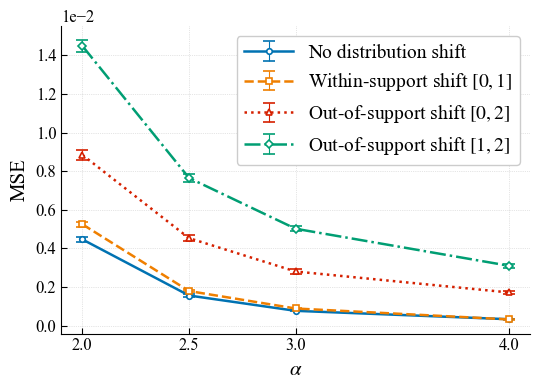

In [ ]:
# plt.style.use('seaborn-v0_8-whitegrid')
# plt.figure(figsize=(8, 6))
# plt.errorbar(
#     [4, 3, 2.5, 2],
#     loss,
#     yerr=1.645*loss_se,
#     fmt='o-',
#     capsize=8,
#     markersize=6,
#     linewidth=3.0,
#     label='No distribution shift'
# )
# plt.errorbar(
#     [4, 3, 2.5, 2],
#     loss_ds,
#     yerr=1.645*loss_se_ds,
#     fmt='o-',
#     capsize=8,
#     markersize=6,
#     linewidth=3.0,
#     label='Within-support shift [0,1]'
# )
# plt.errorbar(
#     [4, 3, 2.5, 2],
#     loss_OOD_02,
#     yerr=1.645*loss_se_OOD_02,
#     fmt='o-',
#     capsize=8,
#     markersize=6,
#     linewidth=3.0,
#     label='Out-of-support shift [0,2]'
# )
# plt.errorbar(
#     [4, 3, 2.5, 2],
#     loss_OOD_12,
#     yerr=1.645*loss_se_OOD_12,
#     fmt='o-',
#     capsize=8,
#     markersize=6,
#     linewidth=3.0,
#     label='Out-of-support shift [1,2]'
# )
# legend = plt.legend(
#     fontsize=20,
#     frameon=True,
#     fancybox=True,
#     framealpha=1.0
# )
# legend.get_frame().set_edgecolor('grey')
# legend.get_frame().set_linewidth(1.0)
# legend.get_frame().set_facecolor('white')
# plt.xlabel(r'$\alpha$', fontsize=20)
# plt.xticks([2.0, 2.5, 3.0, 3.5, 4.0])
# plt.ylabel('MSE', fontsize=20)
# plt.tick_params(axis='both', which='major', labelsize=15)

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "Times New Roman",
#     "text.latex.preamble": r"\usepackage{lmodern}\usepackage[T1]{fontenc}"
# })

# plt.savefig("OOD_loss.pdf", bbox_inches='tight')
# plt.show()


import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "font.family":         "serif",
    "font.serif":          ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset":    "stix",
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "axes.linewidth":      0.8,
    "xtick.direction":     "in",
    "ytick.direction":     "in",
    "xtick.major.size":    4,
    "ytick.major.size":    4,
    "xtick.major.width":   0.8,
    "ytick.major.width":   0.8,
    "axes.grid":           True,
    "grid.linestyle":      ":",
    "grid.linewidth":      0.5,
    "grid.alpha":          0.6,
    "grid.color":          "#aaaaaa",
    "legend.frameon":      True,
    "legend.edgecolor":    "#cccccc",
    "legend.framealpha":   1.0,
    "legend.handlelength": 2.5,
})

# Colorblind-safe palette
BLUE      = "#0072B2"
ORANGE    = "#EF7F00"
VERMILLON = "#D52000"
GREEN     = "#009E73"

z      = 1.645
alphas = [2, 2.5, 3, 4]

shared_kw = dict(
    markerfacecolor="white", markeredgewidth=1.2,
    markersize=4, linewidth=1.8,
    capsize=4, capthick=0.8, elinewidth=0.8,
)

series = [
    (loss[::-1],        loss_se[::-1],        BLUE,      "o-",  "No distribution shift"),
    (loss_ds[::-1],     loss_se_ds[::-1],     ORANGE,    "s--", "Within-support shift $[0,1]$"),
    (loss_OOD_02[::-1], loss_se_OOD_02[::-1], VERMILLON, "^:",  "Out-of-support shift $[0,2]$"),
    (loss_OOD_12[::-1], loss_se_OOD_12[::-1], GREEN,     "D-.", "Out-of-support shift $[1,2]$"),
]

fig, ax = plt.subplots(figsize=(5.5, 4.0))

for vals, errs, color, fmt, label in series:
    ax.errorbar(
        alphas, vals, yerr=z * errs,
        fmt=fmt, color=color, markeredgecolor=color,
        label=label, **shared_kw,
    )

ax.set_xlabel(r"$\alpha$", fontsize=15)
ax.set_ylabel("MSE", fontsize=15)
ax.set_xticks(alphas)
ax.tick_params(labelsize=12)
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.yaxis.get_offset_text().set_fontsize(12)
ax.legend(fontsize=14)

fig.tight_layout()
fig.savefig("OOD_loss.pdf", dpi=300, bbox_inches="tight")
plt.show()